1.Importing libraries

In [9]:
# Importing libraries
import pandas as pd
import numpy as np
%matplotlib inline


#Loading data

In [4]:
df=pd.read_csv('2017_Yellow_Taxi_Trip_Data.csv')

2.EDA
#Exploratory data analysis

In [5]:
df.head()

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,24870114,2,03/25/2017 8:55:43 AM,03/25/2017 9:09:47 AM,6,3.34,1,N,100,231,1,13.0,0.0,0.5,2.76,0.0,0.3,16.56
1,35634249,1,04/11/2017 14:53,04/11/2017 15:19,1,1.80,1,N,186,43,1,16.0,0.0,0.5,4.00,0.0,0.3,20.80
2,106203690,1,12/15/2017 7:26:56 AM,12/15/2017 7:34:08 AM,1,1.00,1,N,262,236,1,6.5,0.0,0.5,1.45,0.0,0.3,8.75
3,38942136,2,05/07/2017 13:17,05/07/2017 13:48,1,3.70,1,N,188,97,1,20.5,0.0,0.5,6.39,0.0,0.3,27.69
4,30841670,2,04/15/2017 11:32:20 PM,04/15/2017 11:49:03 PM,1,4.37,1,N,4,112,2,16.5,0.5,0.5,0.00,0.0,0.3,17.80


In [6]:
df.shape

(22699, 18)

In [11]:
df.columns

Index(['Unnamed: 0', 'VendorID', 'tpep_pickup_datetime',
       'tpep_dropoff_datetime', 'passenger_count', 'trip_distance',
       'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID',
       'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount',
       'tolls_amount', 'improvement_surcharge', 'total_amount'],
      dtype='str')

In [17]:
df_filtered_columns=df[['VendorID','tpep_pickup_datetime','tpep_dropoff_datetime','passenger_count','trip_distance','payment_type','total_amount']]

In [15]:
df_filtered_columns.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,total_amount
0,2,03/25/2017 8:55:43 AM,03/25/2017 9:09:47 AM,6,3.34,1,16.56
1,1,04/11/2017 14:53,04/11/2017 15:19,1,1.80,1,20.80
2,1,12/15/2017 7:26:56 AM,12/15/2017 7:34:08 AM,1,1.00,1,8.75
3,2,05/07/2017 13:17,05/07/2017 13:48,1,3.70,1,27.69
4,2,04/15/2017 11:32:20 PM,04/15/2017 11:49:03 PM,1,4.37,2,17.80


array([[<Axes: title={'center': 'VendorID'}>,
        <Axes: title={'center': 'passenger_count'}>],
       [<Axes: title={'center': 'trip_distance'}>,
        <Axes: title={'center': 'payment_type'}>],
       [<Axes: title={'center': 'total_amount'}>, <Axes: >]], dtype=object)

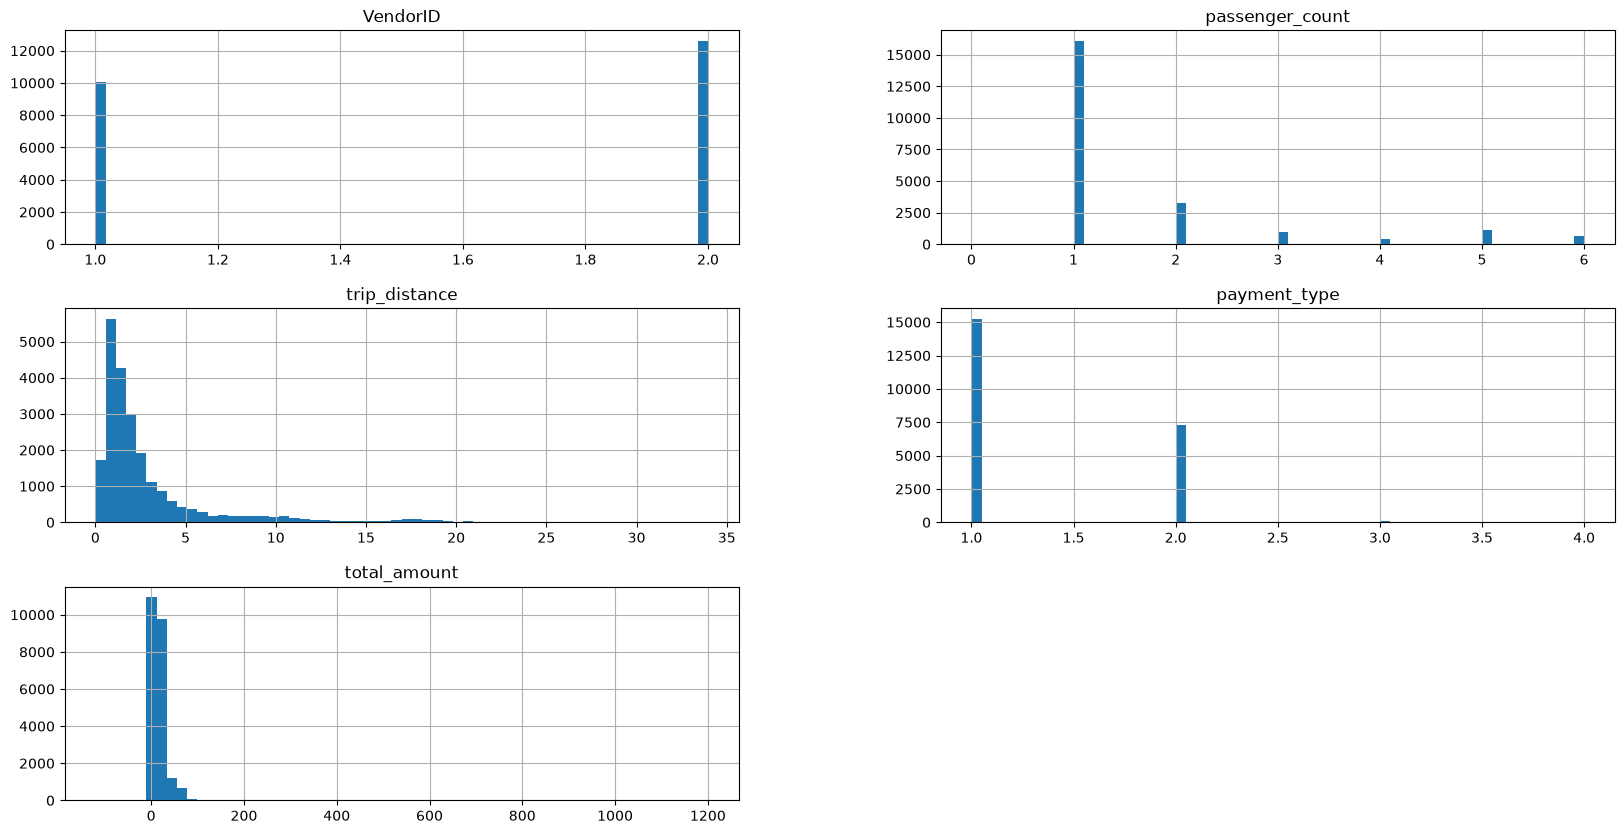

In [20]:
df_filtered_columns.hist(bins=60,figsize=(20,10))

In [21]:
df_filtered_columns['total_amount'].value_counts()

total_amount
7.30     541
7.80     531
6.80     524
8.30     519
8.80     492
        ... 
8.66       1
26.12      1
28.99      1
87.33      1
74.18      1
Name: count, Length: 1369, dtype: int64

In [26]:
df_filtered_columns[df_filtered_columns['total_amount']<0].value_counts()

VendorID  tpep_pickup_datetime    tpep_dropoff_datetime   passenger_count  trip_distance  payment_type  total_amount
2         12/13/2017 2:02:39 AM   12/13/2017 2:03:08 AM   6                0.12           3             -3.8            1
          07/05/2017 11:02        07/05/2017 11:03        1                0.04           3             -3.3            1
          11/16/2017 8:13:30 PM   11/16/2017 8:14:50 PM   2                0.06           4             -4.3            1
          04/06/2017 12:50        04/06/2017 12:52        1                0.25           3             -4.3            1
          01/03/2017 20:15        01/03/2017 20:15        1                0.02           3             -3.8            1
          10/28/2017 8:39:36 PM   10/28/2017 8:41:59 PM   1                0.41           3             -4.8            1
          06/05/2017 17:34        06/05/2017 17:36        2                0.00           4             -4.3            1
          07/09/2017 07:20   

In [ ]:
#It is also worth noting that the negative amounts are of payment_type 3 and 4 which are for No charge and disputes from the dictionary.

In [39]:
df_filtered_columns[df_filtered_columns['total_amount']<0]['payment_type'].value_counts()

payment_type
3    7
4    7
Name: count, dtype: int64

<Axes: >

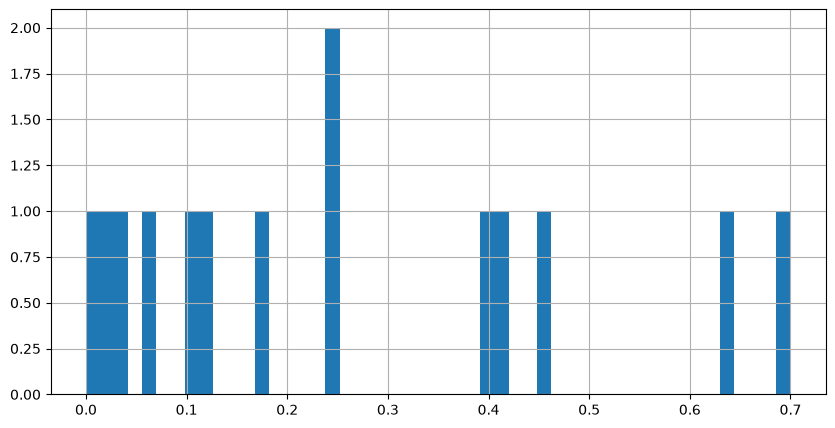

In [43]:
# let's check the trip distance for the negativa amounts
df_filtered_columns[df_filtered_columns['total_amount']<0]['trip_distance'].hist(bins=50, figsize=(10,5))

In [ ]:
#the trips are all below a mile which could explain it.

In [30]:
#TO GET JUST THE TOTAL AMOUNT COLUMN LESS THAN 0, use loc
df_filtered_columns.loc[df_filtered_columns['total_amount']<0,'total_amount'].value_counts()

total_amount
-3.8      3
-4.3      3
-4.8      2
-5.3      2
-5.8      2
-3.3      1
-120.3    1
Name: count, dtype: int64

In [45]:
#There is zero amounts, let's check them out
df_filtered_columns[df_filtered_columns['total_amount']==0]['trip_distance'].value_counts()

trip_distance
0.00    3
7.06    1
Name: count, dtype: int64

In [31]:
df_filtered_columns['payment_type'].value_counts()

payment_type
1    15265
2     7267
3      121
4       46
Name: count, dtype: int64

<Axes: xlabel='index', ylabel='total_amount'>

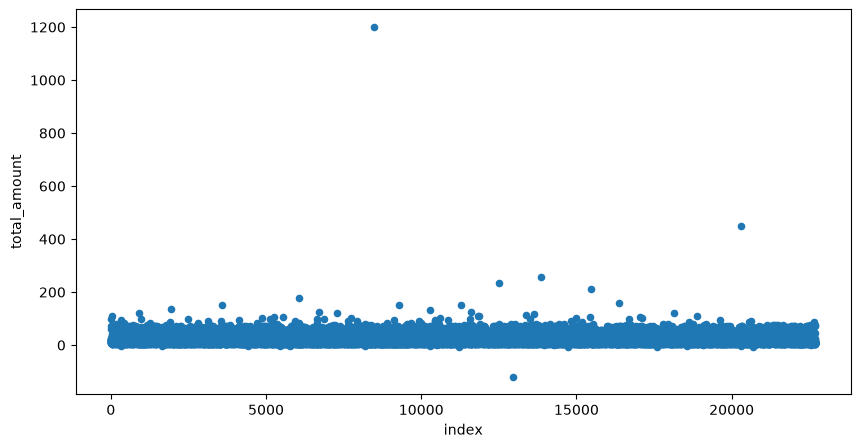

In [34]:
df_filtered_columns.reset_index().plot(kind='scatter',y='total_amount',x='index',figsize=(10,5))

In [36]:
df_filtered_columns[df_filtered_columns['total_amount']>400].value_counts()

VendorID  tpep_pickup_datetime   tpep_dropoff_datetime  passenger_count  trip_distance  payment_type  total_amount
1         02/06/2017 05:50       02/06/2017 05:51       1                2.6            1             1200.29         1
2         12/19/2017 9:40:46 AM  12/19/2017 9:40:55 AM  2                0.0            2             450.30          1
Name: count, dtype: int64

In [ ]:
#There is few outliers, we can drop them


<Axes: xlabel='trip_distance', ylabel='total_amount'>

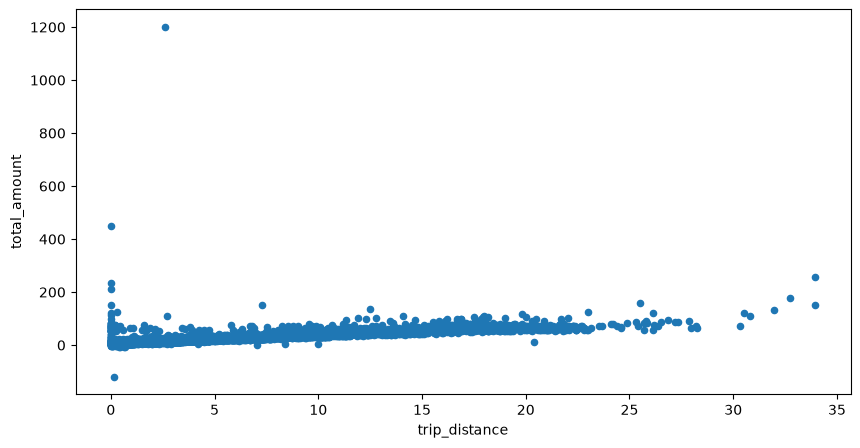

In [37]:
df_filtered_columns.reset_index().plot(kind='scatter',y='total_amount',x='trip_distance',figsize=(10,5))

In [ ]:
#The most amount is not the longest distance and the one slightly above 400 is actually close to zero.This could be a result of clerical error and dropping them would not affect our modelling.

<Axes: >

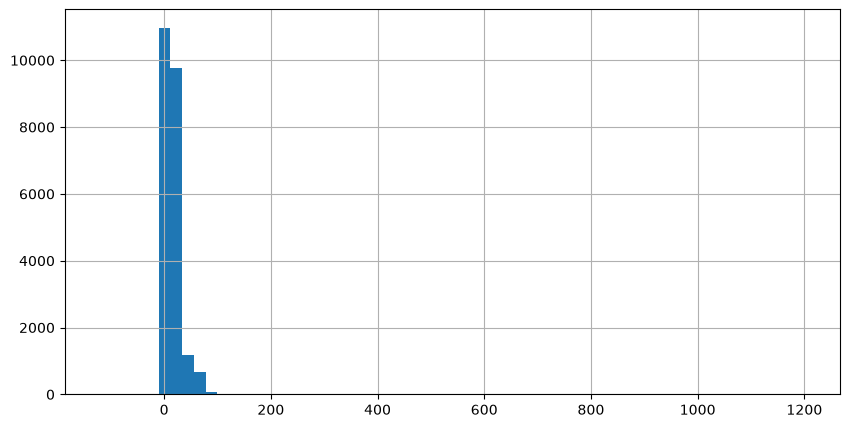

In [62]:
df_filtered_columns['total_amount'].hist(bins=60, figsize=(10,5))

In [53]:
df_filtered_columns[df_filtered_columns['total_amount']>200].shape

(5, 7)

In [63]:
#let's check the average amount spent
df_filtered_columns['total_amount'].mean()

np.float64(16.31050222476761)

In [ ]:
#it is safe to use less than 200 amounts for modelling 

3.Data Cleaning

In [69]:
#let's clean our data by dropping the total amount values below zero as investigated above. Also, data points above 200
df2=df_filtered_columns[(df_filtered_columns['total_amount']>=0)&(df_filtered_columns['total_amount']<200)]

In [67]:
df2.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,total_amount
0,2,03/25/2017 8:55:43 AM,03/25/2017 9:09:47 AM,6,3.34,1,16.56
1,1,04/11/2017 14:53,04/11/2017 15:19,1,1.80,1,20.80
2,1,12/15/2017 7:26:56 AM,12/15/2017 7:34:08 AM,1,1.00,1,8.75
3,2,05/07/2017 13:17,05/07/2017 13:48,1,3.70,1,27.69
4,2,04/15/2017 11:32:20 PM,04/15/2017 11:49:03 PM,1,4.37,2,17.80


In [75]:
print(df.shape)
df2.shape

(22699, 18)


(22680, 7)

checking for missing values

In [76]:
df2.isna().sum()

VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
payment_type             0
total_amount             0
dtype: int64

There is no missing values, awesome.

4.Data Preparation

In [78]:
df_cleaned=df2.copy()

checking the data types

In [79]:
df_cleaned.dtypes

VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count            int64
trip_distance            float64
payment_type               int64
total_amount             float64
dtype: object

changing dates from string to datetime

In [84]:
df_cleaned['tpep_pickup_datetime']=pd.to_datetime(df_cleaned['tpep_pickup_datetime'],errors='coerce')
df_cleaned['tpep_dropoff_datetime']=pd.to_datetime(df_cleaned['tpep_dropoff_datetime'],errors='coerce')

In [ ]:
changing payment type to string since it's a categorical variable

In [85]:
df_cleaned['payment_type']=df_cleaned['payment_type'].astype(str)

In [86]:
df_cleaned.dtypes

VendorID                          int64
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                   int64
trip_distance                   float64
payment_type                        str
total_amount                    float64
dtype: object